In [1]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt

os.chdir("/Users/eloelo/Projects/plant-disease-detection")
print("Working from:", os.getcwd())

train_ds = tf.data.Dataset.load("data/splits_tfds/train")
print("Train split loaded")

Working from: /Users/eloelo/Projects/plant-disease-detection
Train split loaded


2026-09-27 19:30:24.460509: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-09-27 19:30:24.460527: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-09-27 19:30:24.460532: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
I0000 00:00:1790517624.460541  120538 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1790517624.460558  120538 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [2]:
class_names = [
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___healthy",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
]

print("Number of classes:", len(class_names))
print()
for i in range(len(class_names)):
    print(i, class_names[i])

Number of classes: 10

0 Tomato___Bacterial_spot
1 Tomato___Early_blight
2 Tomato___healthy
3 Tomato___Late_blight
4 Tomato___Leaf_Mold
5 Tomato___Septoria_leaf_spot
6 Tomato___Spider_mites Two-spotted_spider_mite
7 Tomato___Target_Spot
8 Tomato___Tomato_mosaic_virus
9 Tomato___Tomato_Yellow_Leaf_Curl_Virus


In [3]:
counts = {}
for name in class_names:
    counts[name] = 0

for image, label in train_ds:
    name = class_names[int(label)]
    counts[name] = counts[name] + 1

for name in counts:
    print(name, "->", counts[name])

print()
print("Total training images:", sum(counts.values()))

Tomato___Bacterial_spot -> 1701
Tomato___Early_blight -> 800
Tomato___healthy -> 1272
Tomato___Late_blight -> 1526
Tomato___Leaf_Mold -> 761
Tomato___Septoria_leaf_spot -> 1416
Tomato___Spider_mites Two-spotted_spider_mite -> 1340
Tomato___Target_Spot -> 1123
Tomato___Tomato_mosaic_virus -> 298
Tomato___Tomato_Yellow_Leaf_Curl_Virus -> 4285

Total training images: 14522


2026-09-27 19:30:25.517298: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


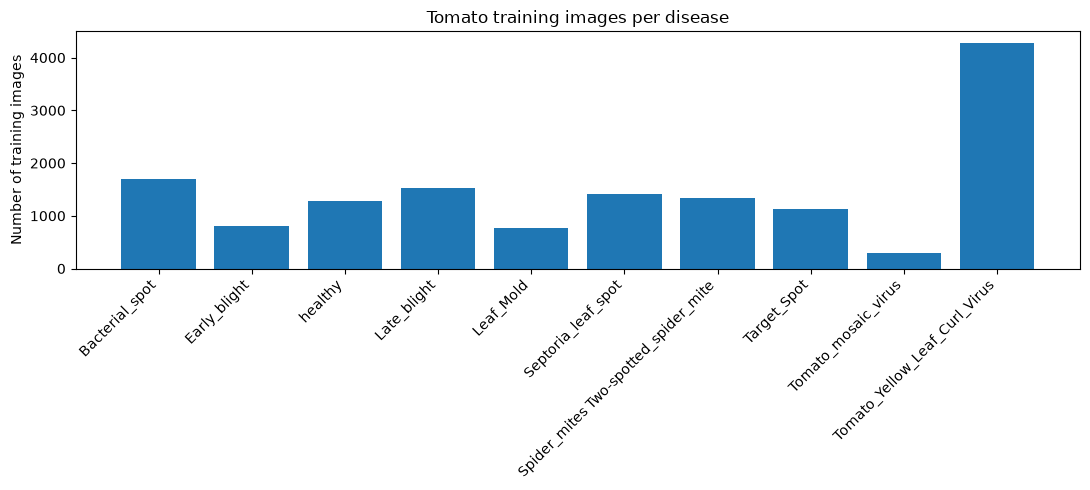

In [4]:
short_names = []
for name in class_names:
    short_names.append(name.replace("Tomato___", ""))

image_counts = []
for name in class_names:
    image_counts.append(counts[name])

plt.figure(figsize=(11, 5))
plt.bar(short_names, image_counts)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of training images")
plt.title("Tomato training images per disease")
plt.tight_layout()
plt.savefig("reports/figures/class_distribution.png", dpi=150)
plt.show()

### Class imbalance
- Largest class: Yellow_Leaf_Curl_Virus, 4,285 training images
- Smallest class: Tomato_mosaic_virus, 298 training images
- About 14 times more images in the largest class than the smallest (4,285 / 298 = 14.4)
- So accuracy alone can look good while small classes do badly
- Used macro-F1 and per-class precision and recall in evaluation (notebook 04) to check the small classes
- Did not use class weighting: the models reached good macro-F1 without it (0.952 on test for MobileNetV2 fine-tuned)

2026-09-27 19:30:25.744074: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-09-27 19:30:26.022960: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-09-27 19:30:27.417937: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


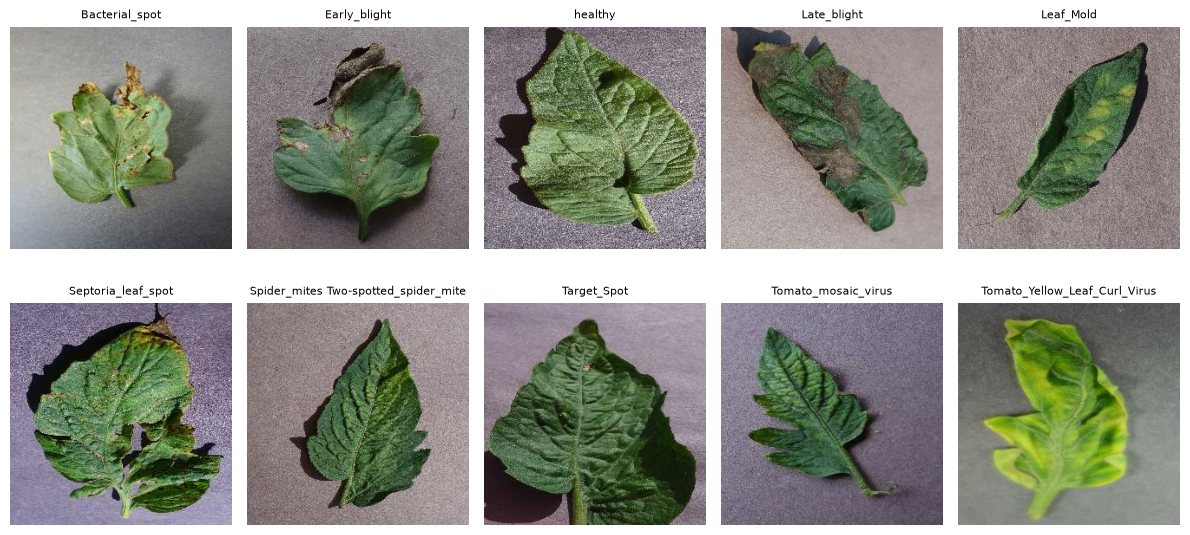

In [5]:
plt.figure(figsize=(12, 6))

for c in range(len(class_names)):
    class_ds = train_ds.filter(lambda image, label: label == c)

    for image, label in class_ds.take(1):
        plt.subplot(2, 5, c + 1)
        plt.imshow(image.numpy())
        plt.title(class_names[c].replace("Tomato___", ""), fontsize=8)
        plt.axis("off")

plt.tight_layout()
plt.savefig("reports/figures/sample_leaves.png", dpi=150)
plt.show()

### What the sample images show
- Every image is a single leaf on a plain grey or purple background (lab photos, not field photos)
- Background colour varies between images, so the model could partly learn the background instead of the disease
- Some diseases look similar: Bacterial_spot, Septoria and Target_Spot all show small dark spots; Early_blight and Late_blight both have dark patches
- Spider_mites and Tomato_mosaic_virus look close to healthy in these samples
- Yellow_Leaf_Curl_Virus is the easiest to spot (clearly yellow) and has the most images
- One image per class is a small sample, so these are first impressions; the confusion matrix in 04 checks them

In [6]:
shapes = set()
dtypes = set()
lowest = 255
highest = 0

for image, label in train_ds:
    shapes.add(tuple(image.shape))
    dtypes.add(image.dtype.name)
    lowest = min(lowest, int(tf.reduce_min(image)))
    highest = max(highest, int(tf.reduce_max(image)))

print("Image shapes found:", shapes)
print("Data types found:", dtypes)
print("Pixel range:", lowest, "to", highest)

Image shapes found: {(256, 256, 3)}
Data types found: {'uint8'}
Pixel range: 0 to 255


### Data-quality checks
- All training images are the same size (256 x 256 x 3) and type (uint8), with pixels from 0 to 255
- So no corrupt, grayscale or wrongly sized images
- Duplicate and leakage checks are in notebook 00: 14 duplicate pairs, all with matching labels, none in the test set

### Preprocessing decisions based on the EDA
- Resize from 256 x 256 to 224 x 224, the input size MobileNetV2 and ResNet50 were trained on
- Normalise pixels in the way each model expects (details in notebook 00)
- Data augmentation (flip, rotation, zoom, contrast) on train only, because leaves appear at different angles and positions, and real photos will vary more than these lab images
- Class imbalance (14x): checked with macro-F1 and per-class metrics instead of accuracy alone
- Lab backgrounds and look-alike diseases noted as limitations, and checked later in the confusion matrix